# KPFM a PINN pro D = 1 × 10⁻¹⁵ m²/s

Kompletně zopakovaný pokus pro opravenou hodnotu **D = 1e-15 m²/s** a původní časové okno **0–600 s**. Časy nebyly prodlouženy. Předchozí pokus pro D = 2e-14 je ve složce `../ukazka_kpfm_design`; rozpracovaný případ 1e-17 je oddělený a není zdrojem zde uvedených výsledků.

**Naučené D = 1.01178e-15 m²/s**, relativní chyba vůči syntetické pravdě **1.18 %**. RMSE všech vynechaných dat **14.79 mV**, vložený šum σ = **15 mV**. Celý řetězec návrh → nezávislá simulace → trénink → validace byl skutečně spuštěn. Obrázky a výsledky jsou v `vystupy/`; notebook `Pruvodce.ipynb` obsahuje obrázky vložené přímo do souboru.

## Spuštění

Z `F:\PINN` v PowerShellu:

```powershell
# Úplná reprodukce včetně kontrol a průvodce:
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\reproduce.py

# Jednotlivé části:
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\run_demo.py all
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\run_demo.py validate
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\time_sensitivity.py
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\mesh_check.py
.\.venv\Scripts\python.exe -m unittest discover -s ukazka_kpfm_D1e-15 -p test_demo.py -v
.\.venv\Scripts\python.exe ukazka_kpfm_D1e-15\create_guide.py
```

`run_demo.py` podporuje také fáze `plan`, `simulate`, `fit`, vlastní `--config`, `--output` a `--steps`. Závislosti: NumPy, SciPy, Matplotlib a PyTorch z `../requirements.txt`. Notebook je volitelný; pro vykonávání jeho buněk je navíc potřeba Jupyter/IPython. Opakovaný běh přepíše vlastní výstupy.


## Fyzika a počáteční stav

Plocha má 10 × 10 µm. Levá elektroda: x = 0–4 µm, y = 4–6 µm, 2 V. Pravá: x = 6–10 µm ve stejném pásu y, 0 V. Mimo kov řešíme homogenní izotropní difuzi potenciálu `∂t φ = D_eff Δφ`; vnější hranice mají nulový tok. Levá elektroda zůstává připojena po celou dobu.

V přesném čase 0⁺ má dielektrikum 0 V. Počáteční stav je nezávislý na D, a proto je **citlivost na D v přesném čase 0 všude nulová**, včetně konvolvovaného signálu. Náboj kovu ani okamžité 3D elektrostatické pole po sepnutí nejsou samostatně řešené. Pravá elektroda na 0 V nemusí být fyzikálně bez náboje.

Odhadované D je efektivní parametr rozlévání potenciálu. Při lokální kapacitě a ohmické plošné vodivosti odpovídá vztahu `D_eff = G_sheet / C_A`; samotný fit jej neurčuje jako mikroskopickou difuzivitu konkrétního iontu. V tomto pokusu je známá počáteční mapa silný předpoklad. Pro prostorově odlišné povrchy, například odstraněné HDMS v obdélníku, by bylo nutné model rozšířit.


## 1. Nový návrh míst pro časové okno 600 s

Návrh používá citlivost rozmazaného signálu vůči `ln D` pro předběžné hodnoty 2,5e-16; 5e-16; 1,5e-15; 3e-15 m²/s. Nečte syntetickou pravdu ani zašuměná data. Chamtivě maximalizuje průměrný logaritmus determinantu Fisherovy matice pro `(ln D, ln a, b)`, takže zohledňuje i neznámou kalibraci. Jde o heuristiku s pokrytím tří pásů y, nikoli zaručené globální optimum.

Kandidáti jsou zahuštění u čel i bočních hran elektrod. Vybírá se 24 míst na dielektriku, 4 kalibrační reference a 8 míst vyhrazených pro kontrolu. Vybraná místa mají odstup alespoň 0,70 µm; kontrolní místa jsou rezervovaná samostatně. Nominální časy jsou **0, 5, 15, 30, 60, 120, 240, 450 a 600 s**. Časový protokol je předem zvolený, není optimalizovaný.

Každý odečet trvá v této simulaci 0,05 s. Skutečné časy obsahují pořadí snímání; poslední bod průchodu je o 1,75 s později než jeho začátek. Pro přístroj je třeba zahrnout i skutečné přesuny a ustálení.

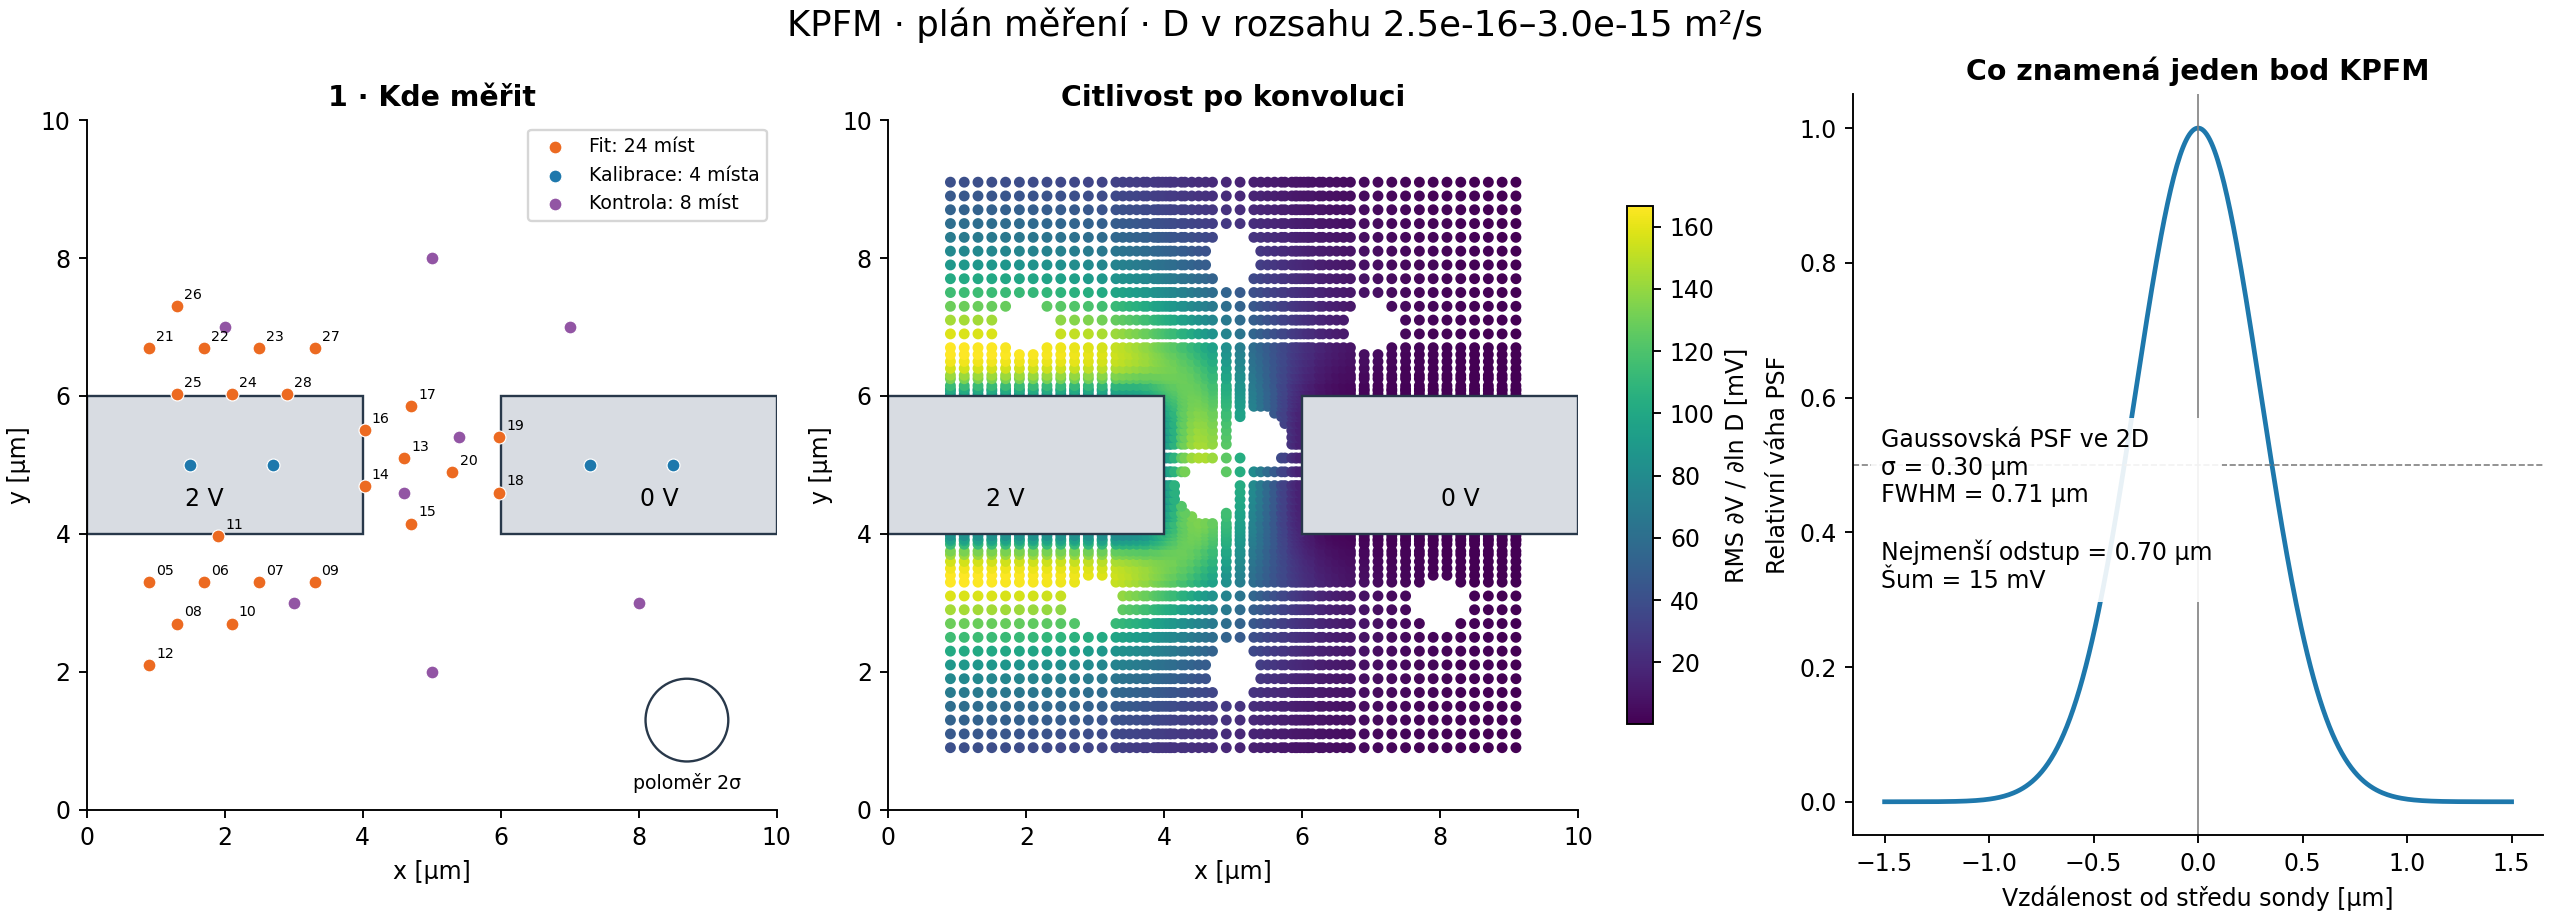


## 2. Syntetická data s prostorovou PSF a šumem

Pozorovací model je `V = a (Kσ * φ) + b + ε`, kde Kσ je normalizovaná 2D Gaussova PSF se σ = 0,30 µm a FWHM ≈ 0,71 µm. Konvoluce zahrnuje kov i dielektrikum, včetně míchání přes hrany. Na neuniformní mřížce používáme přesný integrál Gaussianu přes každou obdélníkovou buňku; konstantní pole se zachová.

Pravda: D = 1e-15 m²/s, zisk a = 0,72, offset b = 25 mV. Po konvoluci se přidává nezávislý Gaussův šum σ = 15 mV, seed 2026. Celkem vznikne 324 odečtů. Čistá pravda a vložený šum jsou uložené zvlášť v souborech `*_DO_NOT_FIT*`.

Nezávislý generátor používá konečné objemy a řídkou maticovou exponenciálu. Skutečná jemná síť má **92 × 92 buněk**, nejmenší krok **12.5 nm** u hran. Inverze používá jinou síť, **52 × 52 buněk**, s nejmenším krokem **25 nm**. Počty `truth_grid` a `inverse_grid` v konfiguraci označují pouze základní rovnoměrné dělení před zjemněním.

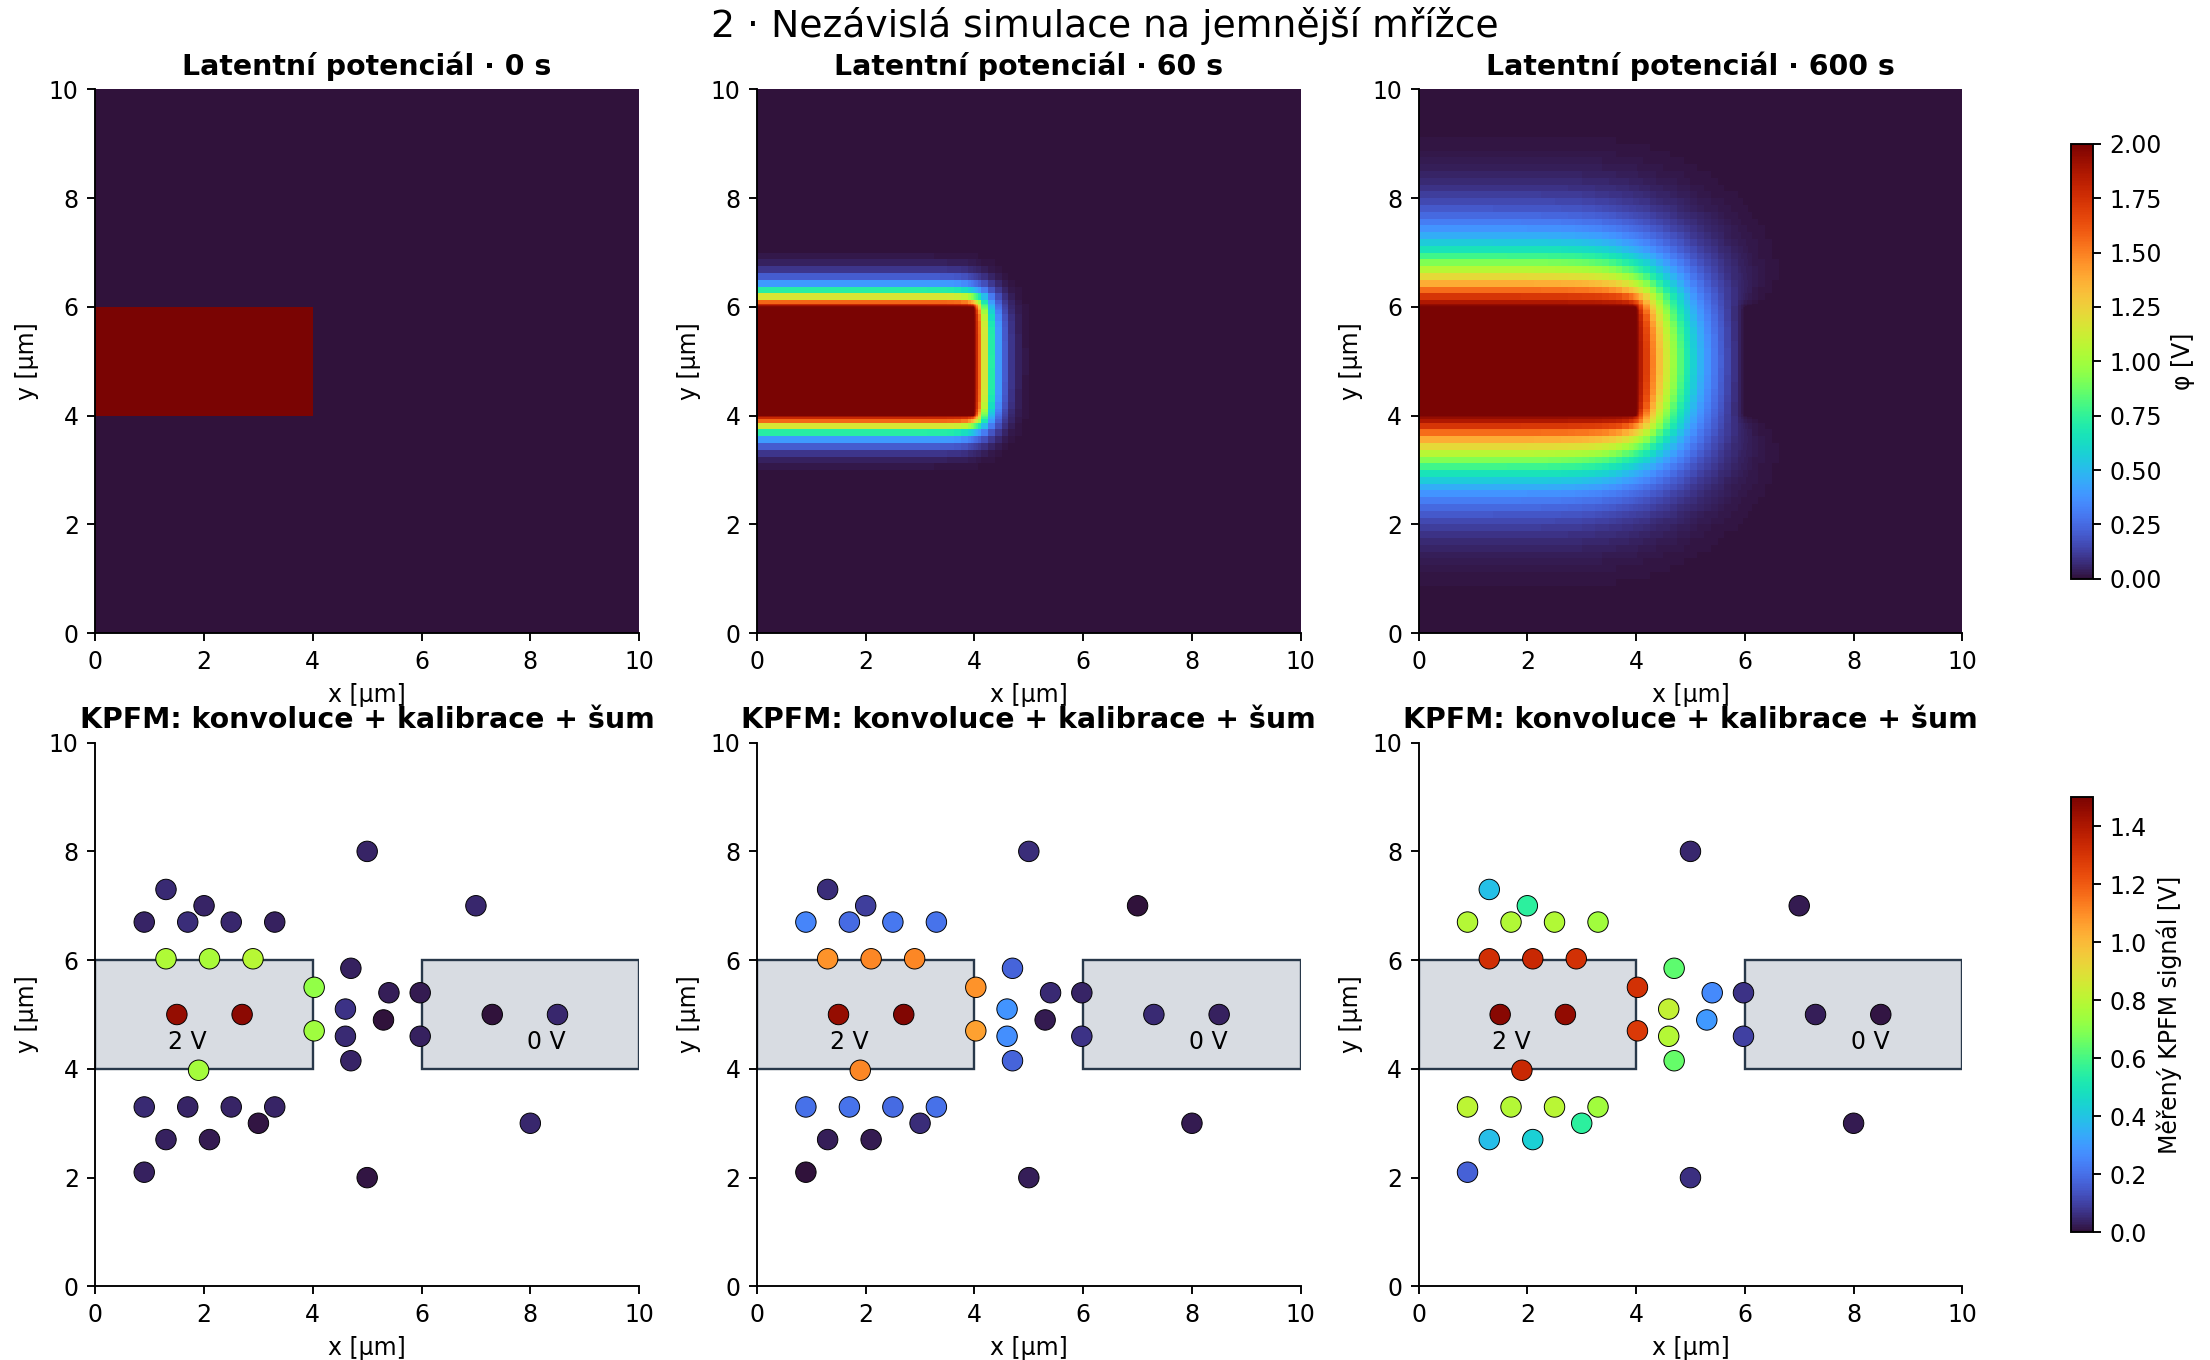


## 3. Inverzní PINN a oddělené ověření

Síť používá úplnou prostorovou vlastní bázi váženého konečně objemového operátoru. Na neuniformní mřížce je Laplacián symetrizovaný hmotnostmi buněk. Pole má tvar

\[
\phi_\theta=\phi_\infty+\sum_k c_kv_k\exp[-\lambda_kq_\theta(\tau)],
\quad q_\theta(\tau)=\tau\exp f_\theta(\tau).
\]

`fθ` je MLP se dvěma skrytými vrstvami po 24 neuronech a aktivací tanh. Síť se učí čas q, kalibraci a samostatně kladné α; fyzikální loss vynucuje `dq/dτ = α`, kde `D = α L²/T`, `L = 10 µm`, `T = 602 s`. Časová derivace používá PyTorch autograd. D není vložené do dopředného výpočtu signálu a není předem fixované numerickou inverzí.

Je to PINN se silně zabudovaným známým lineárním prostorovým modelem pro konstantní skalární D. Není to obecný MLP se vstupy x, y, t. Počáteční stav a prostorové okraje jsou splněné konstrukcí. Báze není truncovaná. Na neuniformní mřížce je exportované vnitřní PDE RMS počítané s plošnými vahami buněk.

Trénink: 3 000 kroků Adam, 96 nových kolokačních časů na krok. Inicializace D = 3e-16 m²/s; další běhy začínají i z 3e-15 m²/s. Datová loss je dělená rozptylem šumu, fyzikální loss má váhu 100 a numerické škálování α = 0,006. To je měřítko loss, nikoli fixace D.

Celý průchod ve 120 s a všech 8 prostorových kontrolních míst jsou vynechané z fitu i kalibrace. **224 tréninkových a 100 kontrolních odečtů**. `fit()` nedostává syntetickou pravdu. Reziduum je ověřené na 501 dalších časech; kontroluje se také monotonicita neuronového času.

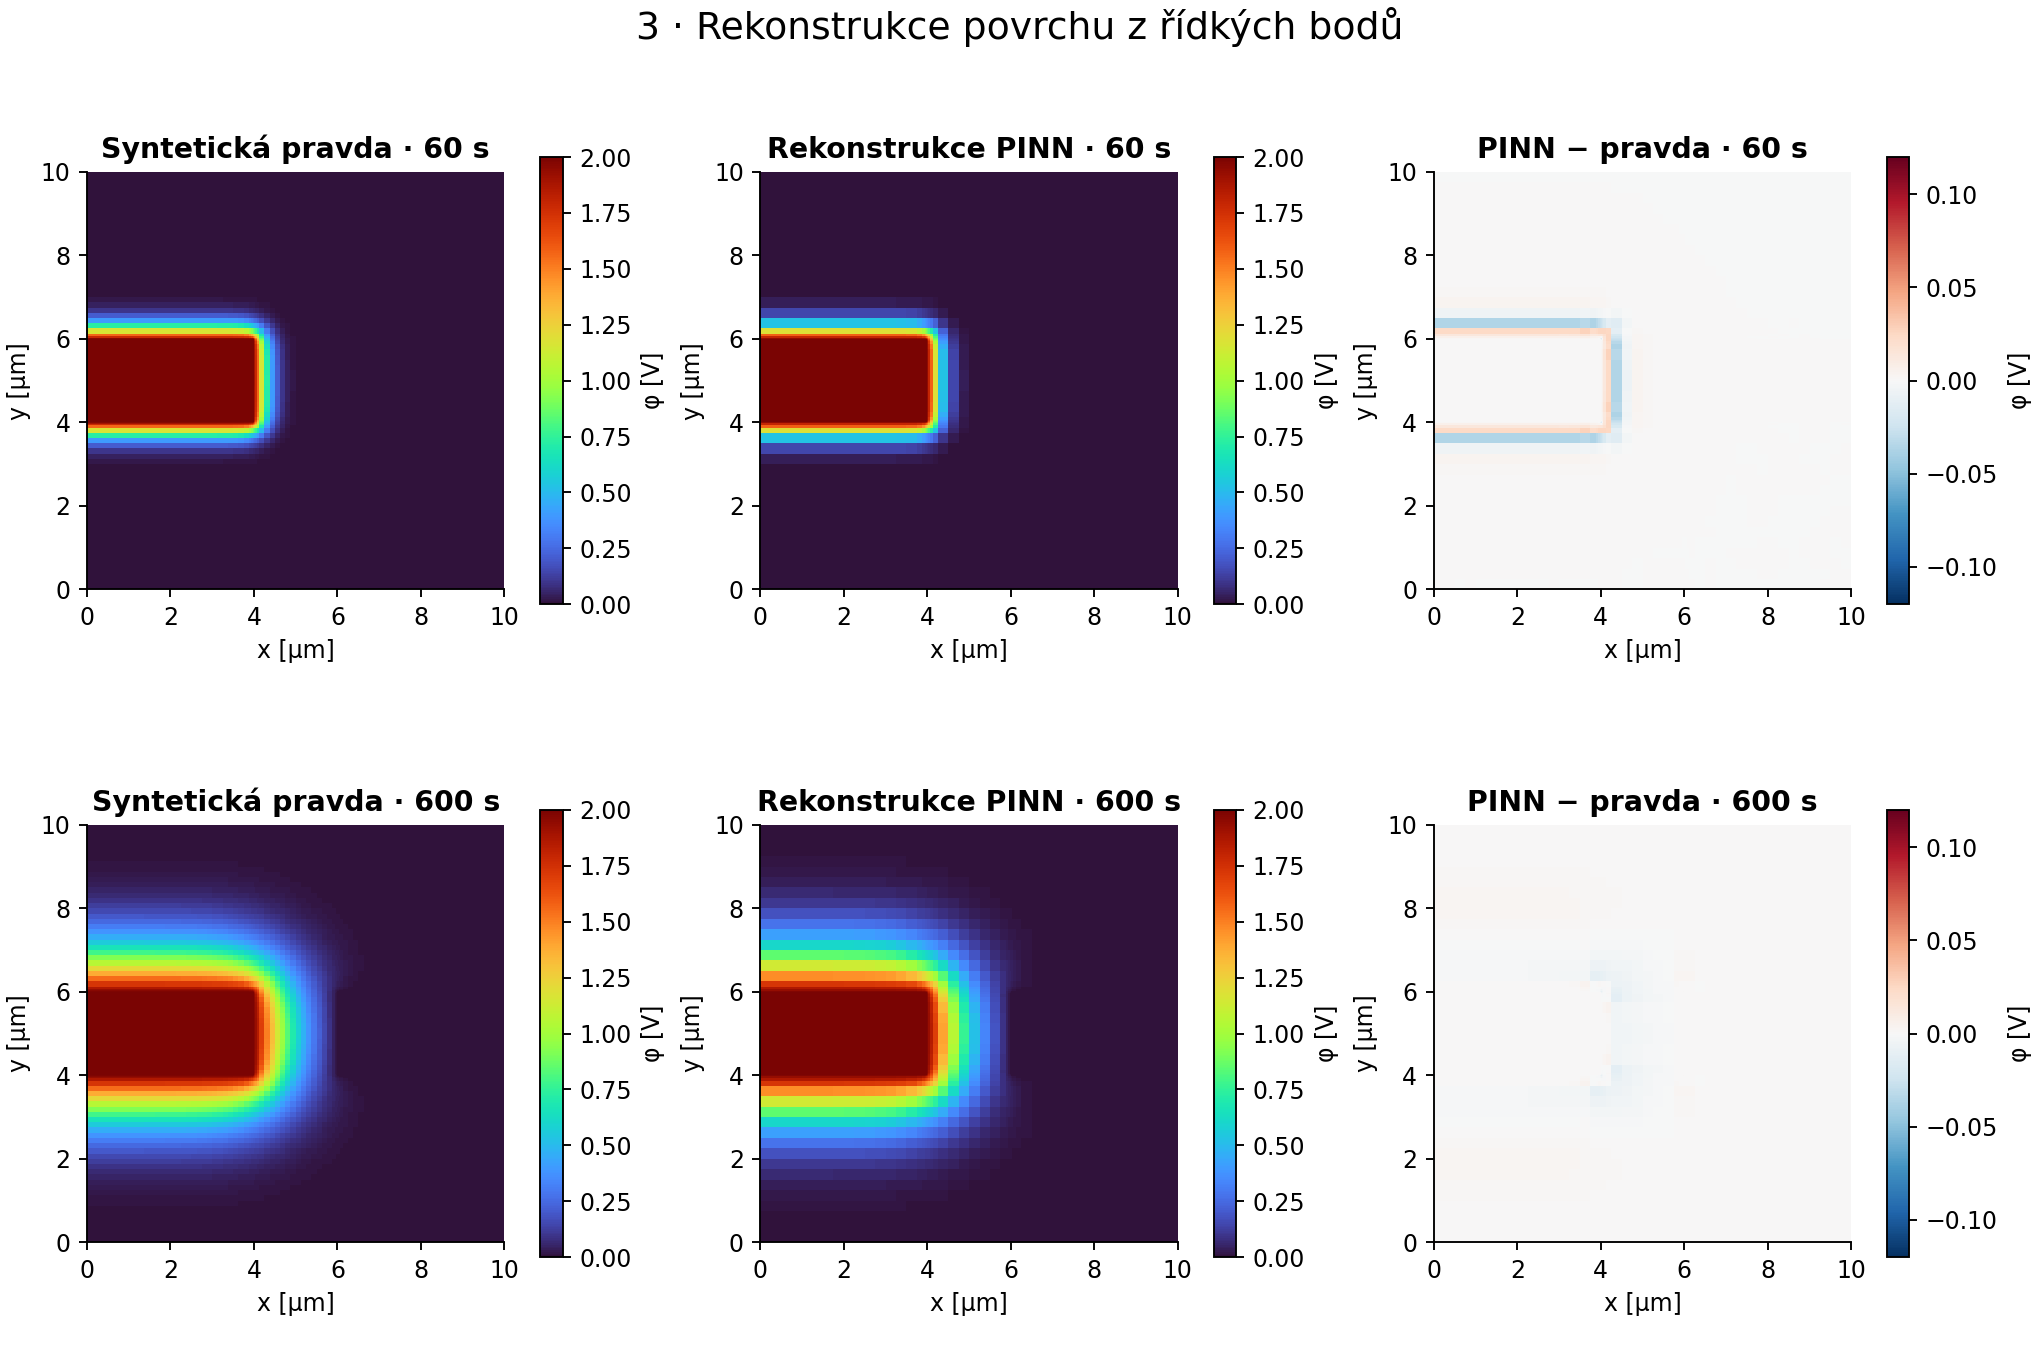


## Výsledky skutečně spuštěných běhů

| Běh | Počáteční D [m²/s] | Odhad D [m²/s] | Chyba vůči pravdě | Kontrolní RMSE [mV] |
|---|---:|---:|---:|---:|
| PINN, seed 7 | 3.000e-16 | 1.01178e-15 | 1.18 % | 14.79 |
| PINN, seed 19 | 3.000e-16 | 1.01174e-15 | 1.17 % | 14.79 |
| PINN, seed 31 | 3.000e-15 | 1.01182e-15 | 1.18 % | 14.79 |
| Kontrolní chybný model bez PSF | 3.000e-16 | 1.21354e-15 | 21.35 % | 54.65 |

Hlavní běh: tréninkové RMSE 16.16 mV, vynechaný čas 14.75 mV, prostorová kontrola 15.38 mV. Naučená kalibrace a = 0.72213, b = 25.56 mV. Relativní RMS rezidua neuronového času 0.157 %.

Kontrolní model bez PSF nahrazuje konvoluci bodovým odečtem nejbližší buňky a znovu učí i kalibraci. Jeho relativní fyzikální reziduum je 11.72 %, takže tento kontrolní běh není řádně konvergovaný alternativní odhad D. Ukazuje současný nesoulad s daty i fyzikou při chybném pozorovacím modelu. Rozptyl seedů není interval spolehlivosti.

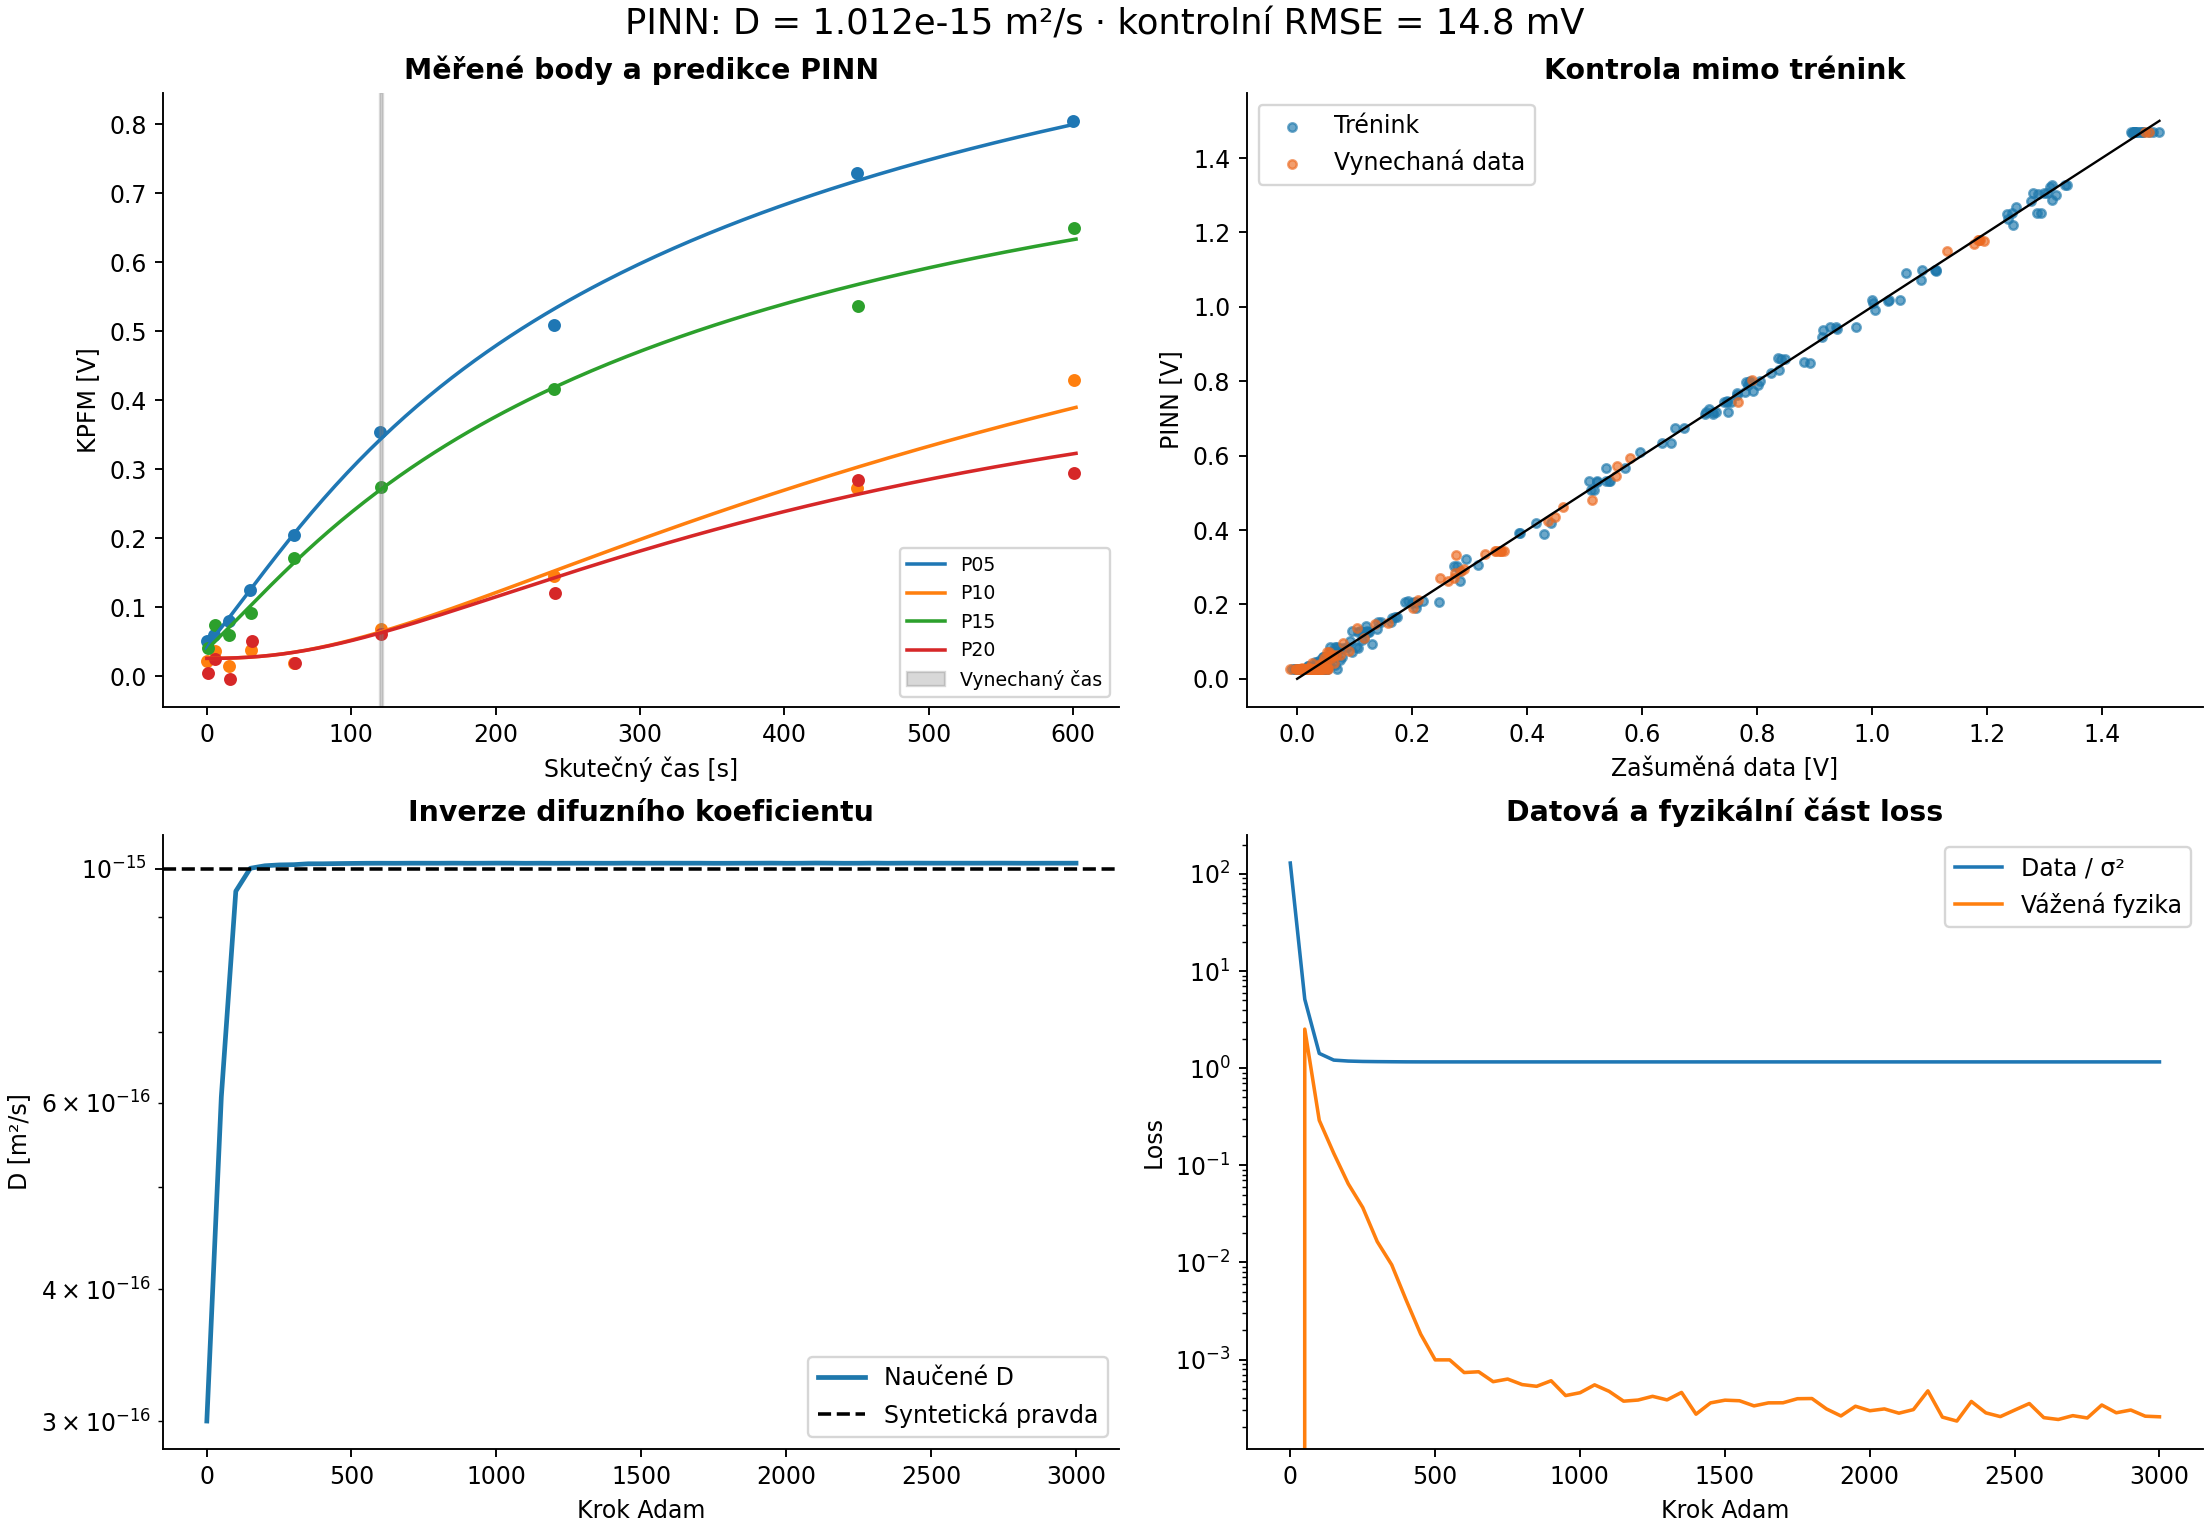


## Prostorová a časová citlivost

Pro konstantní D, konstantní okrajová napětí, počáteční stav nezávislý na D a pevnou prostorovou PSF závisí signál na součinu D × t. Proto platí `∂V/∂ln D = t ∂V/∂t`. V čase 0 je citlivost na D nulová; po ustálení opět zaniká. Maxima se pro jiné D přibližně posouvají jako 1/D.

V tomto desetiminutovém okně se informace přesouvá od okolí levé elektrody do jejího blízkého okolí a mezery. Levé rohy dosahují globálního maxima až později. Vysoké souhrnné citlivosti rohů z původního případu D = 2e-14 se sem automaticky nepřenášejí.

| Místo [µm] | Globální maximum [s] | Maximum v okně 600 s? | Citlivost v 600 s [mV / ln D] |
|---|---:|---|---:|
| Levý dolní roh (0,9; 0,9) | 5286 | ne | 34.95 |
| U spodní hrany (2; 3,9) | 84 | ano | 84.84 |
| U čela levé elektrody (4,025; 5) | 60 | ano | 54.19 |
| Střed mezery (5; 5) | 377 | ano | 221.51 |
| Dál od hrany (2; 3,5) | 196 | ano | 210.74 |

Tabulka je pro nominální D = 1e-15 a plánovací zisk 0,70, nikoli z fitu zašuměných dat. Maxima jsou orientační a závisí na síti a logaritmickém časovém kroku. Citlivost například 100 mV / ln D znamená asi 9,5 mV změny signálu při zvýšení D o 10 %, nikoli 100 mV pro libovolnou malou změnu D.

Mapy mají stejnou barevnou škálu pro všechny časy. Samostatný detail 0–600 s ukazuje i změnu signálu od zapnutí. Odvozené citlivosti byly ověřené centrálními diferencemi vůči D i času; maximální absolutní rozdíl citlivosti na ln D byl 3.69e-10 V.

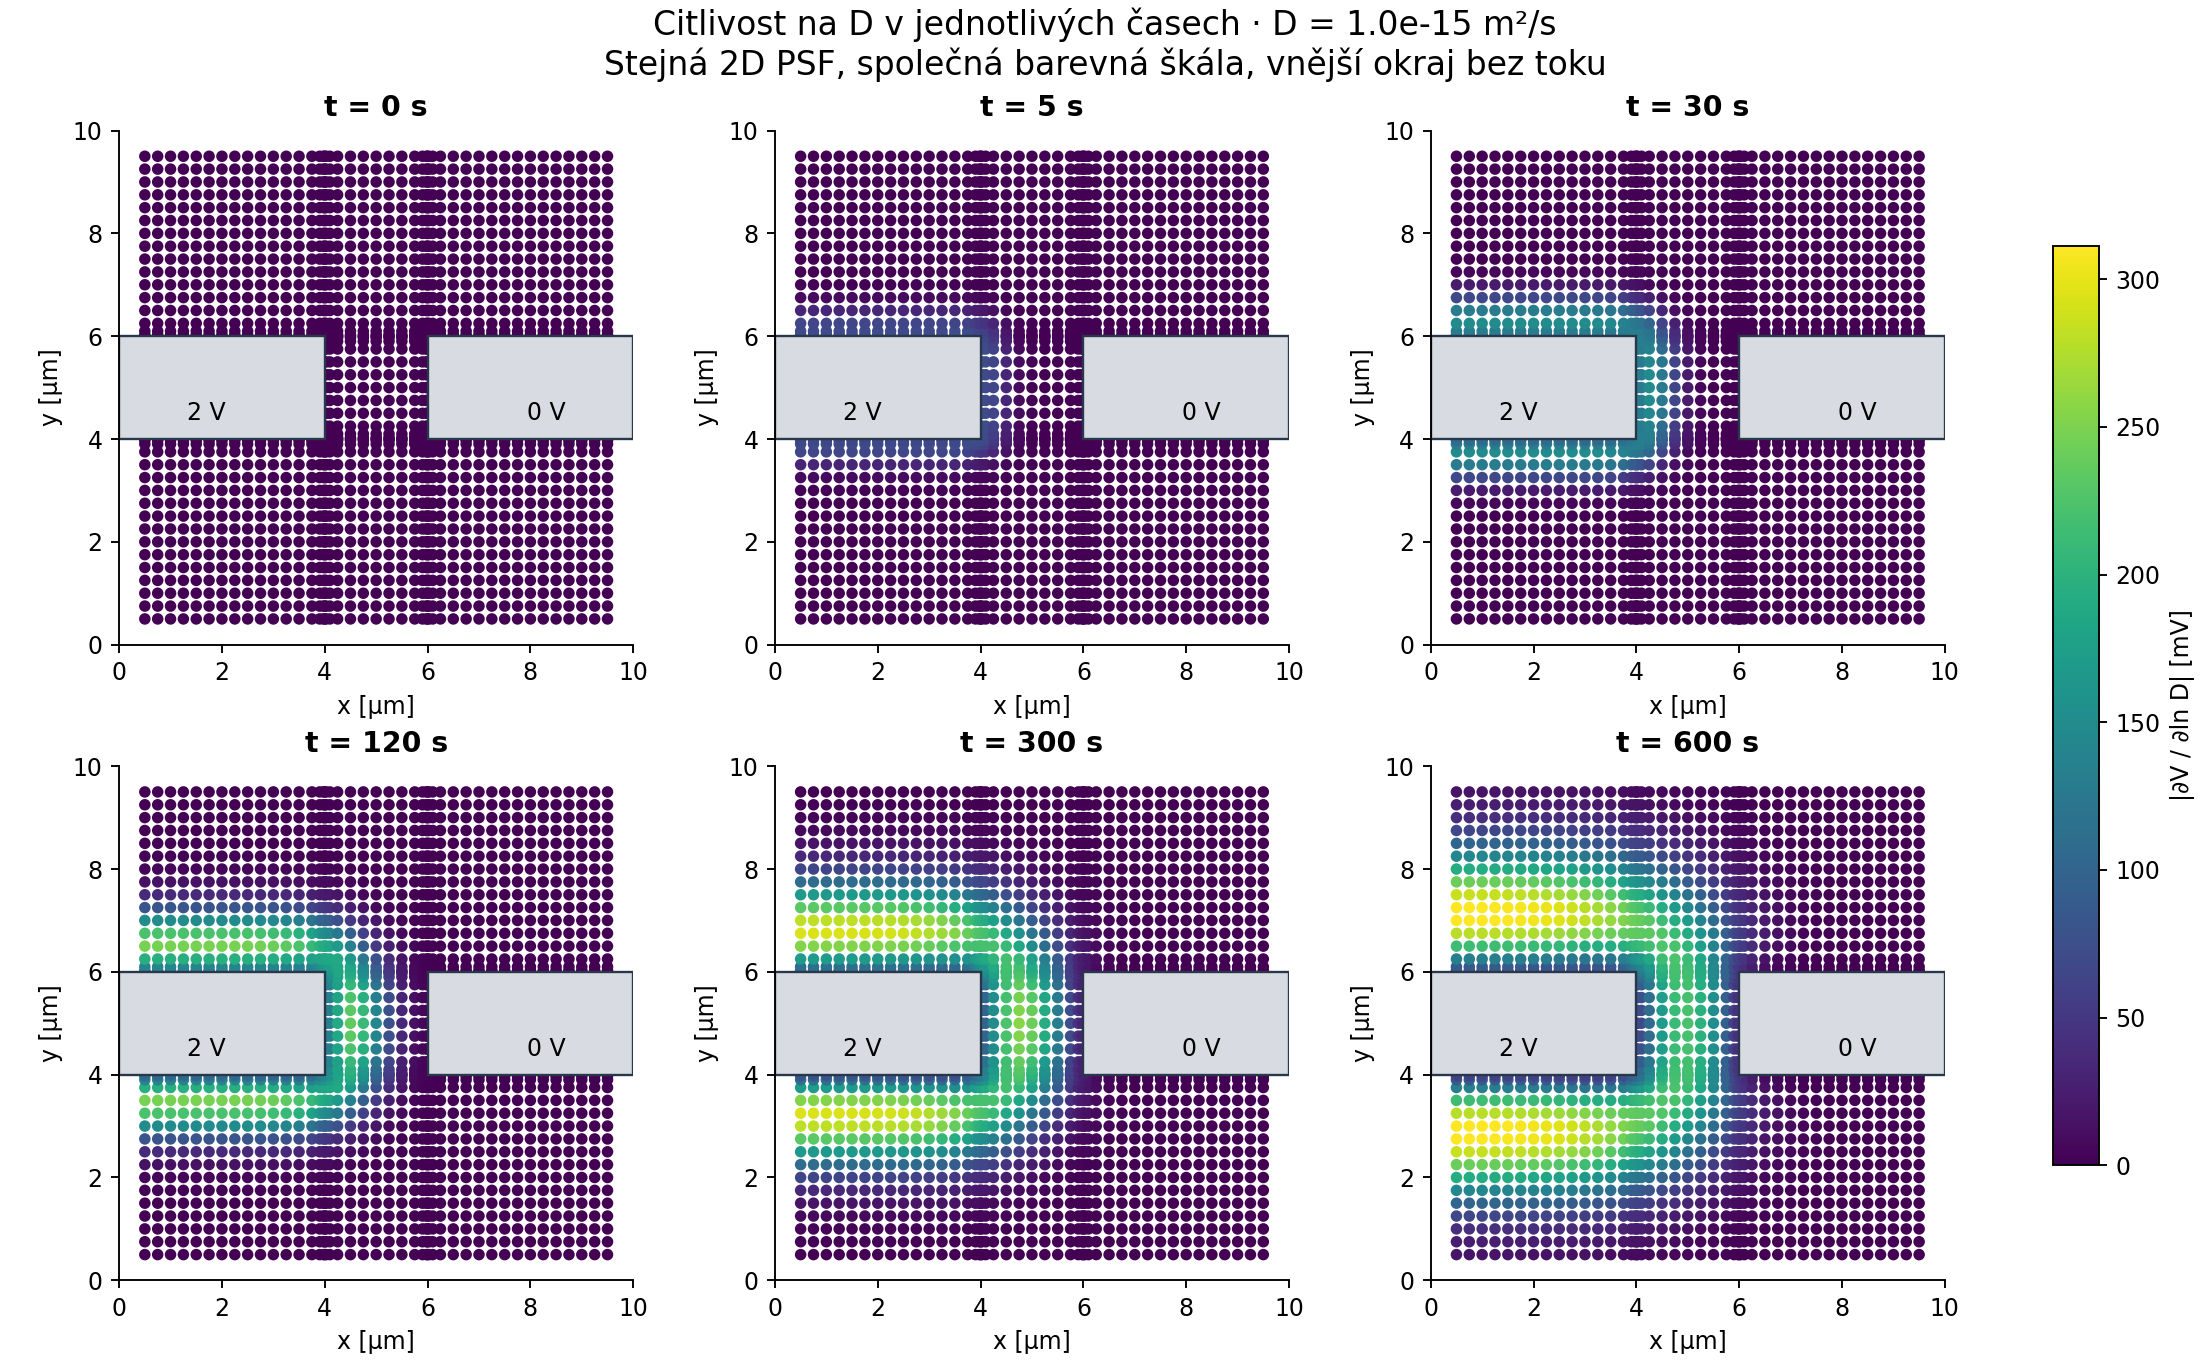

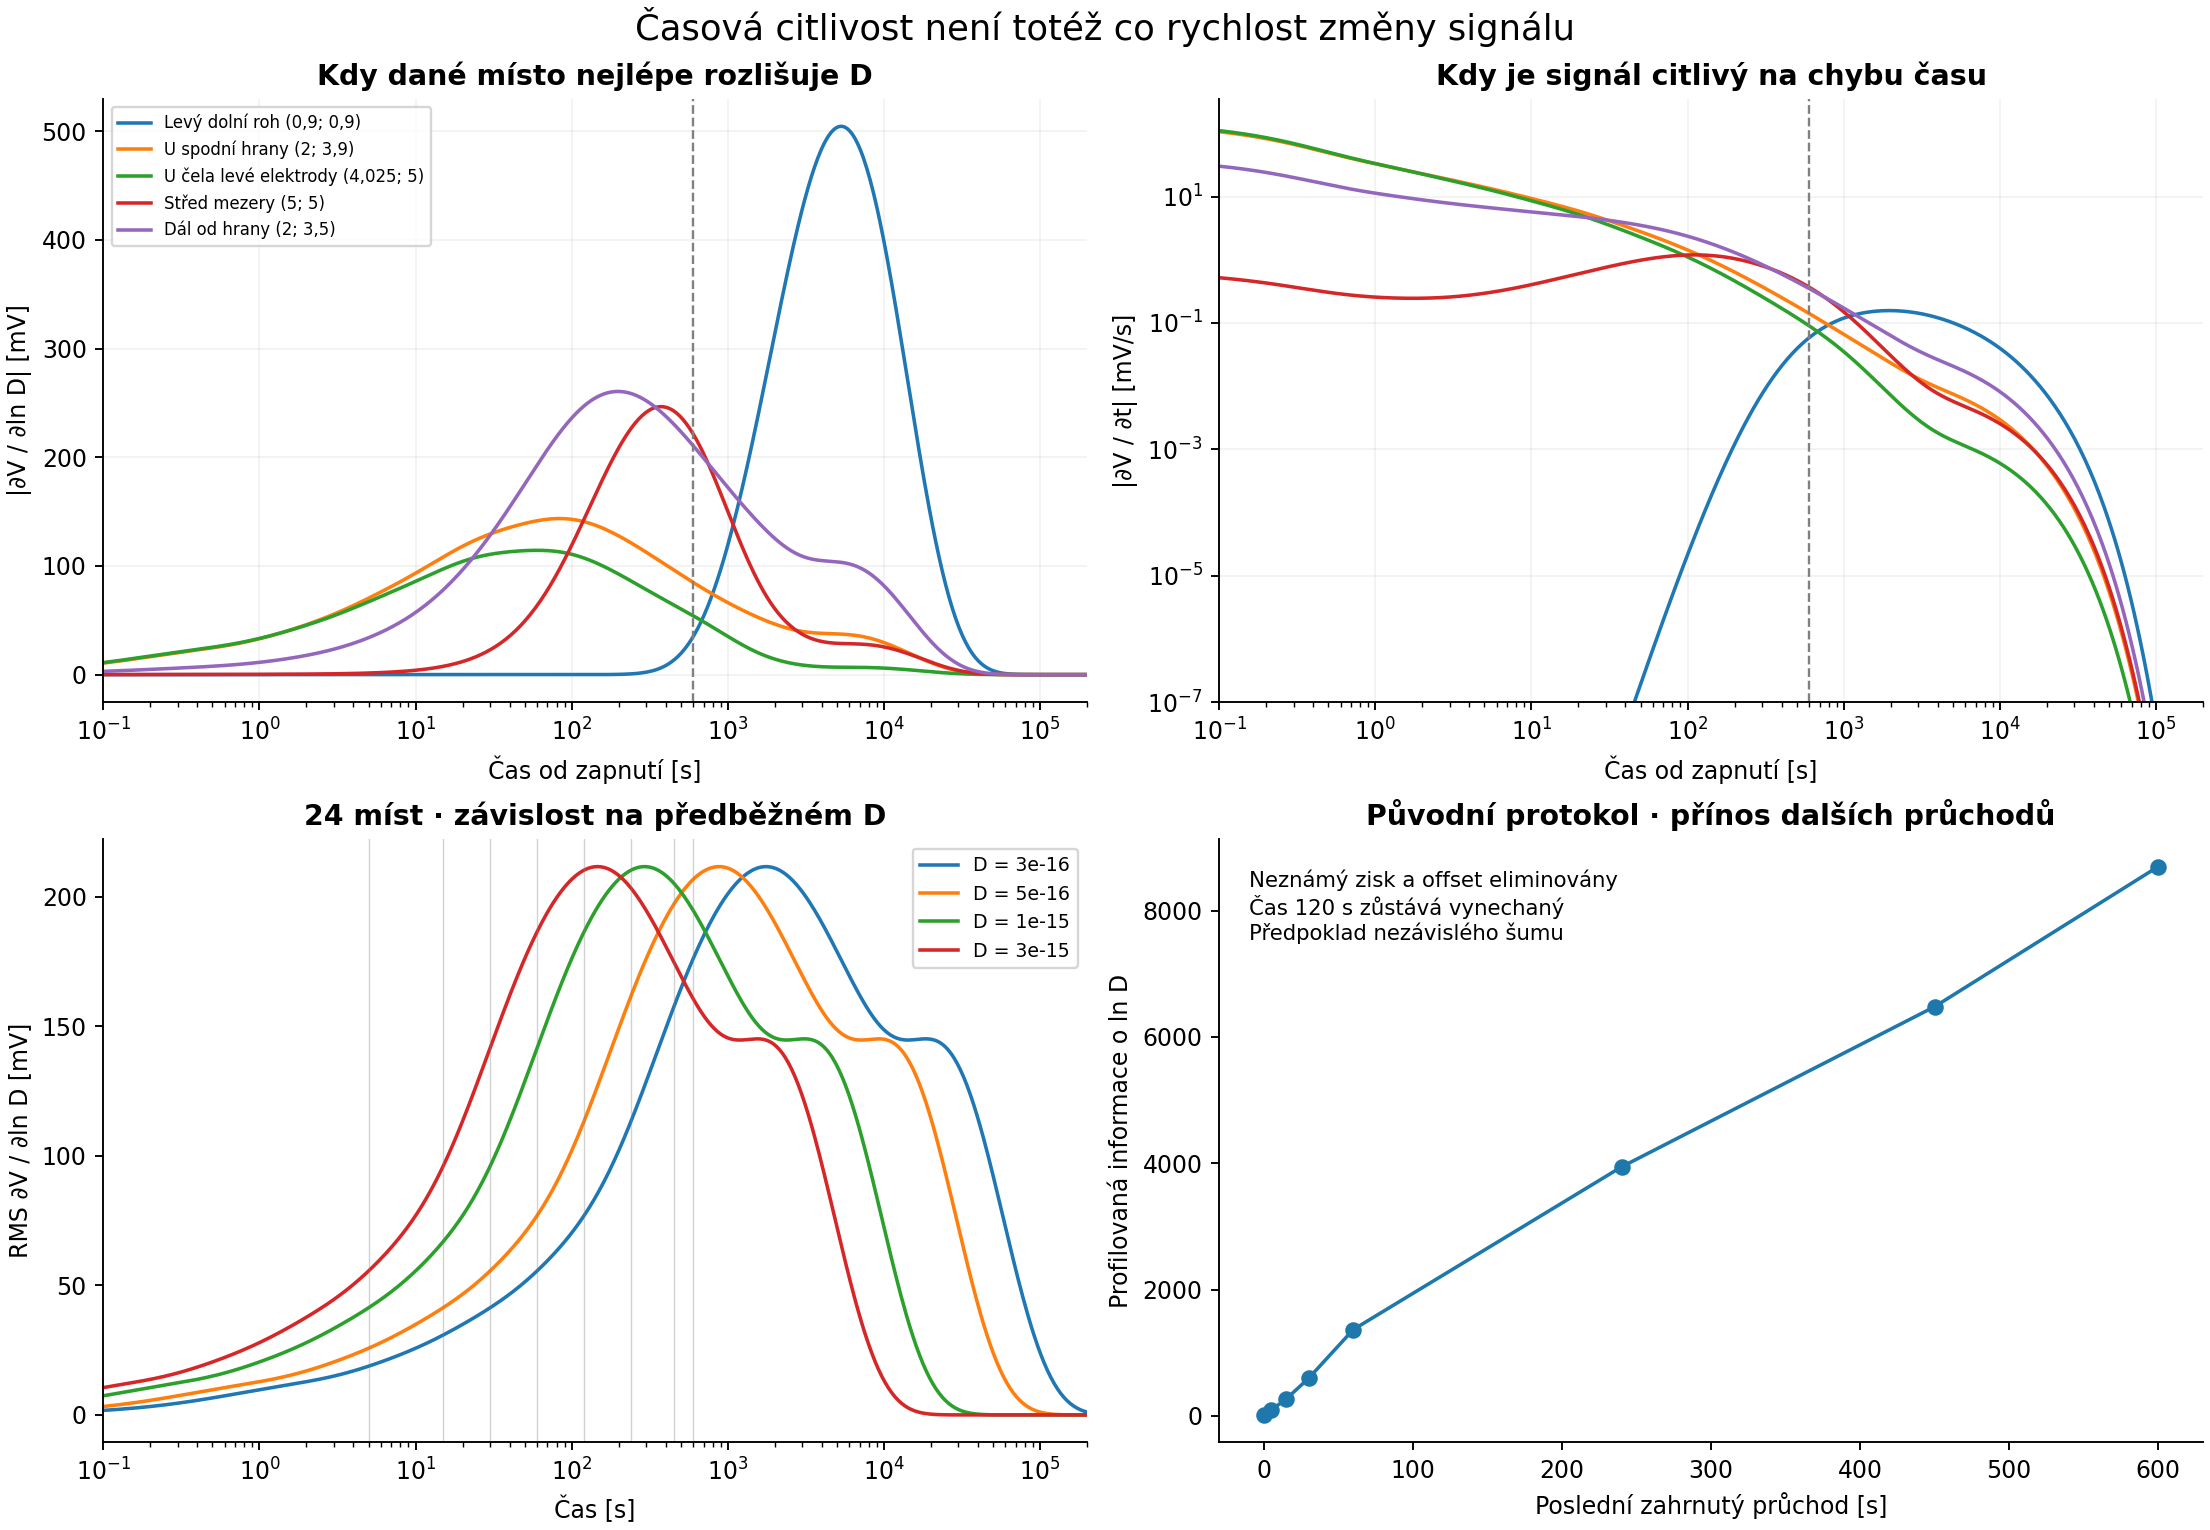

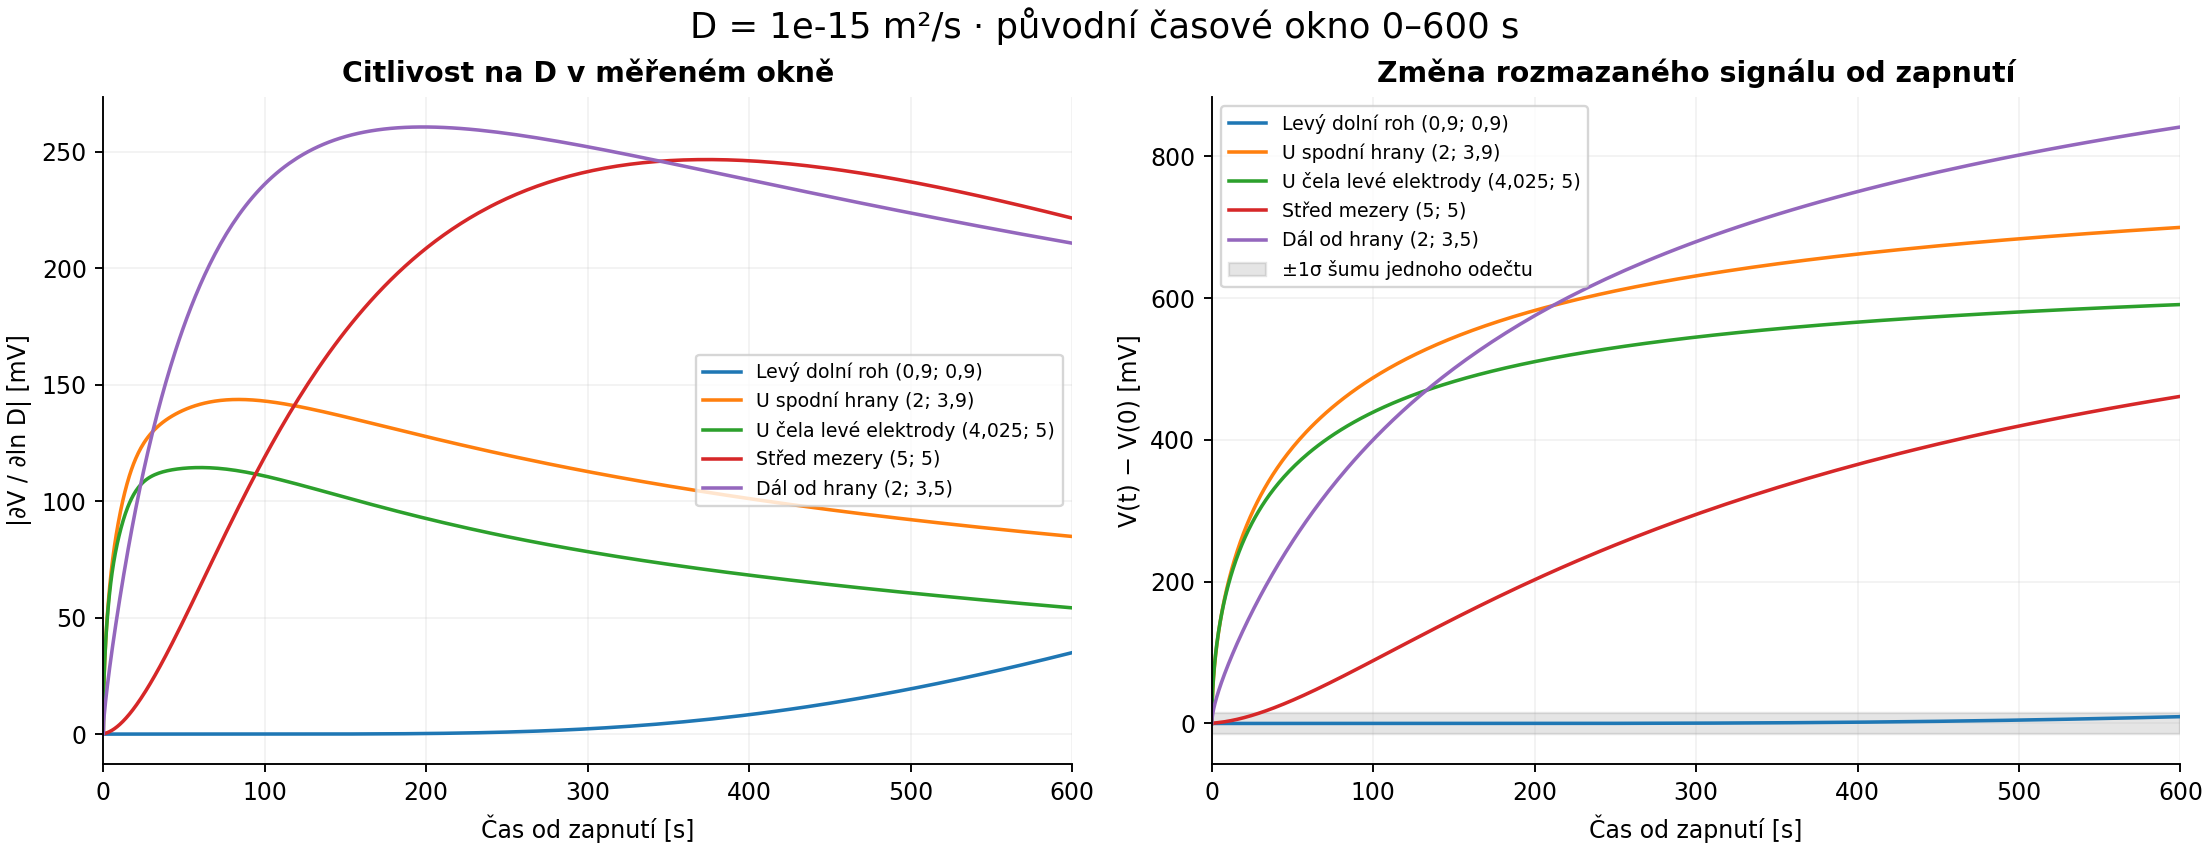


## Kontrola prostorové diskretizace

Před finálním během byla nalezena odchylka hrubší sítě v řádu vloženého šumu; finální inverzní i generující síť byly proto zjemněné. `mesh_check.py` porovnává dopředné signály na **stejných výsledných místech a nominálních časech**, při stejném D a zisku, bez optimalizace neuronové sítě. Reference je nejjemnější ze čtyř sítí, nikoli prokázané přesné kontinuální řešení.

| Základní dělení | Nejmenší krok [nm] | Skutečná síť | RMS vůči nejjemnější [mV] | Maximum odchylky [mV] |
|---:|---:|---:|---:|---:|
| 20 | 25 | 38 × 38 | 10.71 | 32.63 |
| 40 | 25 | 52 × 52 | 2.99 | 9.28 |
| 40 | 12.5 | 60 × 60 | 2.52 | 9.71 |
| 80 | 12.5 | 92 × 92 | 0.00 | 0.00 |

Soubor `kontrola_hrubsi_mrizky/` obsahuje předběžné číselné výsledky před zjemněním; jde o odlišný návrh míst a jinou síť, nikoli další seed finálního běhu. Šest automatických kontrol ověřuje PSF, vážený operátor, shodu vlastní báze s nezávislou řídkou propagací, fyzikální gradienty, časový protokol a obnovení D s predikcí vynechaných dat.

## Soubory a omezení

V `vystupy/`: `measurement_plan.csv`, `acquisition_plan.json`, `measurements.csv`, `model.pt`, `fit_summary.json`, `synthetic_recovery_check.json`, `validation_runs.json`, `predictions.csv`, `loss.csv`, `reconstruction.npz`, `time_sensitivity.csv`, `time_sensitivity_summary.json`, `mesh_convergence.csv` a sedm obrázků. Pole se zobrazují přes skutečné nerovnoměrné stěny buněk, takže zjemněná oblast není na obrázcích prostorově roztažená.

Známá počáteční mapa, pevná PSF, homogenní konstantní D a nulový tok na vnější hranici jsou podmínky tohoto kontrolovaného pokusu. Pro skutečný výřez většího vzorku je nutné prověřit vnější hranici. Drift, korelovaný šum, časová odezva přístroje, pasti, únik do objemu a různé materiálové oblasti se samostatně nemodelují. Úspěšná obnova syntetického D není experimentální potvrzení těchto předpokladů.

Pozorovací model a původní odvození jsou vysvětlené také v `../ukazka_kpfm_design/README.md`. Zde žádné hodnoty z dodaného obrázku nejsou použity jako tréninková data.


In [ ]:
from pathlib import Path
import json
root = Path.cwd()
if (root / "ukazka_kpfm_D1e-15").is_dir():
    root = root / "ukazka_kpfm_D1e-15"
assert (root / "config.json").exists(), "Otevřete notebook ze složky ukázky nebo F:/PINN."
print((root / "vystupy" / "fit_summary.json").read_text(encoding="utf-8"))
# Volitelné opakování celého pokusu (přepíše vlastní výstupy):
# import subprocess, sys
# python = root.parent / ".venv" / "Scripts" / "python.exe"
# subprocess.run([str(python) if python.exists() else sys.executable,
#                 str(root / "reproduce.py")], check=True)
